# Step__1: Importing the required libraries

In [ ]:
#Import required libraries

import os  # Used to interact with the operating system, files, folders, and environment variables
import re
import time
import random     # Used to generate random numbers and select random elements
import warnings   # Used to display, manage, filter, or suppress warning messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import Model
from tensorflow.keras import layers
from tensorflow.keras import callbacks # Imports tools used to monitor and control the model-training process

warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step__2: Set random seed

In [ ]:
#Set random seed

SEED = 42     # Define a fixed seed for reproducible results

os.environ["PYTHONHASHSEED"] = str(SEED)  # Set Python's hash seed for consistent hashing
random.seed(SEED)    # Set the seed for Python's random module
np.random.seed(SEED) # Set the seed for NumPy's random operations
tf.random.set_seed(SEED)    # Set the seed for TensorFlow's random operations
print("Random seed:", SEED)  # Display the selected random seed

Random seed: 42


# Step 4: Uploading IMDB Dataset

In [ ]:
#Upload IMDB Dataset.csv

uploaded_files = files.upload()

CSV_PATH = next(iter(uploaded_files))

print("Uploaded file:", CSV_PATH)

Saving IMDB Dataset.csv to IMDB Dataset.csv
Uploaded file: IMDB Dataset.csv


# other -option uploading through the google drive
 Connecting Google Drive with Google Colab

In [ ]:

#Connecting Google Drive with Google Colab
# Import the Google Drive module
from google.colab import drive

# Mount Google Drive inside Google Colab
drive.mount("/content/drive")

Mounted at /content/drive


#step__4_seeing the datset

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/projects /madrid_software_file/projects/ai_project_movie_review/IMDB Dataset.csv")

In [ ]:
df.head(1)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive


#Step__5_checking the shape and column_names

In [ ]:
# Step: seeing  the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

display(df.head())

Dataset shape: (50000, 2)

Column names:
Index(['review', 'sentiment'], dtype='object')


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


#step__6__Checking the dataset information

In [ ]:
# Checking the dataset information

print("Dataset information:")
df.info()



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


#step__7__cheking the data_set_null_values

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())




Missing values:
review       0
sentiment    0
dtype: int64


#step__8_cheking the _duplicate _value

In [ ]:
print("\nDuplicate rows:")
print(df.duplicated().sum())




Duplicate rows:
418


#step__9__cheking the  number of difference classification

In [ ]:
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())


Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


# Step__10__: Remove missing and duplicate records

In [ ]:
# Remove missing and duplicate records

df = df[["review", "sentiment"]]

df = df.dropna()

df = df.drop_duplicates()

df = df.reset_index(drop=True)   # Reset the DataFrame index and remove the old index

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (49582, 2)


#step__11__Encode the target column

In [ ]:
#Encoding the target column

df["label"] = df["sentiment"].str.lower().map({             # Convert sentiment text into numerical labels
    "negative": 0,                                          # Assign 0 to negative reviews
    "positive": 1                                           # Assign 1 to positive reviews
})

df = df.dropna(subset=["label"])                            # Remove rows containing missing or invalid labels

df["label"] = df["label"].astype("int32")                    # Convert the label column to 32-bit integer type

display(df.head())

,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


# Step__12__: Create a text-cleaning function

In [ ]:
# Creating a text-cleaning function
def clean_review(text):

    text = str(text)  # Convert the input value into a string

    text = re.sub(
        pattern=r"<br\s*/?>",  # Find HTML line-break tags such as <br>, <br/> and <br />
        repl=" ",              # Replace each matching tag with a space
        string=text,           # Apply the replacement to the review text
        flags=re.IGNORECASE    # Match both uppercase and lowercase tags
    )

    text = re.sub(
        pattern=r"<,  [^>]+>"  # Find all remaining HTML tags
        repl=" ",              # Replace each HTML tag with a space
        string=text            # Apply the replacement to the review text
    )

    text = re.sub(
        pattern=r"[^a-zA-Z0-9\s!?'.,]",  # Find unwanted characters
        repl=" ",                         # Replace unwanted characters with spaces
        string=text                       # Apply the replacement to the review text
    )

    text = re.sub(
        pattern=r"\s+",  # Find one or more consecutive whitespace characters
        repl=" ",        # Replace consecutive whitespace with a single space
        string=text      # Apply the replacement to the review text
    )

    text = text.strip().lower()  # Remove outer spaces and convert text to lowercase

    return text  # Return the cleaned review text


df["clean_review"] = df["review"].apply(clean_review)  # Clean every review and store it in a new column

display(
    df[["review", "clean_review", "label"]].head()     # Display the first five original reviews, cleaned reviews and labels
)

,review,clean_review,label
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming tec...,1
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei's love in the time of money is a...,1


# step__13__Visualizing the exact class distribution

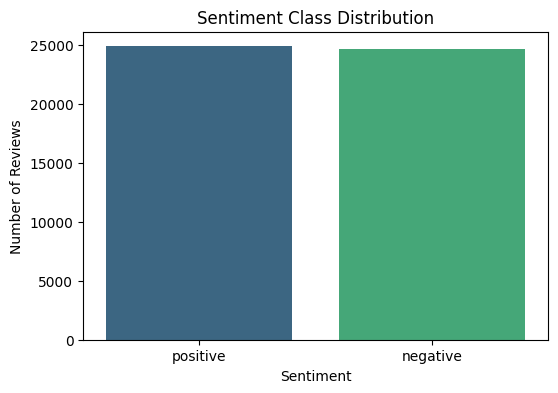

In [ ]:
#Visualize class distribution

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="sentiment",
    palette="viridis"
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# step__14___Separating input and target variable

In [ ]:
# Separating input and target

X = df["clean_review"].values
y = df["label"].values

print("Total reviews:", len(X))
print("Total labels:", len(y))

Total reviews: 49582
Total labels: 49582


# step__15___Creating train, validation and test sets accordingly

In [ ]:
# Creating train, validation and test sets

X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,   # Ensure the same split every time the code runs
    stratify=y           # Maintain the original class distribution in both sets

)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=SEED,
    stratify=y_remaining  #Maintain the same class distribution from y_remaining in both new datasets
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Testing samples:", len(X_test))

print("\nPositive-label ratio:")
print("Training:", y_train.mean())
print("Validation:", y_validation.mean())
print("Testing:", y_test.mean())

Training samples: 39665
Validation samples: 4958
Testing samples: 4959

Positive-label ratio:
Training: 0.5018782301777386
Validation: 0.5018152480839048
Testing: 0.5019157088122606


#step___16___Defining common model parameters

In [ ]:
# Define common parameters that will be used by all text-classification models

VOCAB_SIZE = 20_000         # Keep the 20,000 most frequent words from the dataset
MAX_LENGTH = 250            # Make every review exactly 250 tokens long
EMBEDDING_DIMENSION = 128    # Represent every token using a vector containing 128 numbers

BATCH_SIZE = 128             # Process 128 reviews together during one training step
EPOCHS = 6                   # Train the model on the complete training dataset 6 times

# Display the selected model parameters
print("Maximum vocabulary:", VOCAB_SIZE)
print("Sequence length:", MAX_LENGTH)
print("Embedding dimension:", EMBEDDING_DIMENSION)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Maximum vocabulary: 20000
Sequence length: 250
Embedding dimension: 128


# Step__17__: Create the TextVectorization layer

In [ ]:
# Create the TextVectorization layer
vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,                 # Keep a maximum of 20,000 tokens in the vocabulary
    output_mode="int",                     # Convert every token into its corresponding integer ID
    output_sequence_length=MAX_LENGTH,     # Make every review exactly 250 tokens long
    standardize=None                       # Do not clean text again because it is already cleaned
)

# Create a TensorFlow Dataset using only the training reviews
training_text_dataset = tf.data.Dataset.from_tensor_slices(
    X_train                                # Use only training text to prevent data leakage
).batch(
    512                                    # Process 512 reviews at a time while learning vocabulary
)

# Learn the vocabulary from the training reviews
vectorizer.adapt(
    training_text_dataset                  # Scan training batches and learn the most frequent tokens
)

# Print the total number of tokens learned by the vectorizer
print(
    "Actual vocabulary size:",             # Description displayed before the result
    len(vectorizer.get_vocabulary())       # Get and count all learned vocabulary tokens
)

Actual vocabulary size: 20000


# step__18___Check text vectorization

In [ ]:
# Cheking my text vectorization ie representations in number or matrices

sample_review = X_train[0]

tokenized_review = vectorizer(
    tf.constant([sample_review])
)

print("Original review:")
print(sample_review)

print("\nTokenized review:")
print(tokenized_review.numpy())

print("\nTokenized shape:")
print(tokenized_review.shape)

Original review:
i am one of jehovah's witnesses and i also work in an acute care medical facility. over the years i have seen people die from hemolytic reactions to blood transfusions, have attended numerous conferences on blood born pathogens, and have seen several patients become seriously ill from pathogens induced by transfused blood. i have also heard several jehovah's witnesses being told that they will die if they refuse blood and after 26 years in the field i have never actually seen it happen, leaving the question, is it really unreasonable to refuse blood transfusions or is the community at large benefiting from the battle on this issue? the issue for jehovah's witnesses is a moral one. you must abstain from blood is not an ambiguous statement. thank you for this movie and allowing comments on it.

Tokenized review:
[[    9   218    28     5     1  5899     4     9    84   206     8    31
      1   470  2844     1   117     2   181     9    25   122    90   912
     34     1

#step__19___Creating the  TensorFlow input pipelines properly

In [ ]:
#Creating TensorFlow input pipelines

# Create a reusable function for building a TensorFlow dataset
def create_tensorflow_dataset(texts, labels, training=False):

    # Combine every text review with its corresponding sentiment label
    dataset = tf.data.Dataset.from_tensor_slices(
        (texts, labels)        # Create (review, label) pairs
    )                          # Prepare the next batch in the background while the model processes the current batch

    # Shuffle the dataset only when it is being used for model training
    if training:

        # Randomly rearrange training samples before creating batches
        dataset = dataset.shuffle(
            buffer_size=len(texts),               # Use all provided reviews in the shuffle buffer
            seed=SEED                             # Produce the same shuffled order on repeated runs
        )

    # Group multiple review-label pairs into one batch
    dataset = dataset.batch(
        BATCH_SIZE                                # Process 128 reviews together in one training step
    )

    # Prepare the next batch while the model processes the current batch
    dataset = dataset.prefetch(
        tf.data.AUTOTUNE                          # Automatically select an efficient prefetch size
    )

    # Return the completely prepared TensorFlow dataset
    return dataset


# Create the training dataset
train_dataset = create_tensorflow_dataset(
    X_train,                                      # Training reviews
    y_train,                                      # Corresponding training labels
    training=True                                 # Enable shuffling for training data
)


# Create the validation dataset
validation_dataset = create_tensorflow_dataset(
    X_validation,                                 # Validation reviews
    y_validation                                  # Corresponding validation labels
                                                 # training=False is used by default, so no shuffling
)


# Create the testing dataset
test_dataset = create_tensorflow_dataset(
    X_test,                                       # Testing reviews
    y_test                                        # Corresponding testing labels
                                                 # training=False is used by default, so no shuffling
)


# Confirm that all TensorFlow datasets were created
print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


# Step__20___: creating___Custom attention-pooling layer

In [ ]:
'''
__init__()  → Automatically executes when an object or layer is created.

self        → Represents the current object or instance of the class.

super()     → Provides access to the parent class.

**kwargs    → Receives multiple named arguments as a dictionary.

super().__init__(**kwargs)
            → Initializes the parent Keras layer using the provided settings.
'''

In [ ]:
'''
WHAT IS A LAYER?

A layer is a basic building block of a neural network.

A layer receives input data, performs a mathematical operation on it,
and produces output.

Basic flow:

Input → Layer → Output

Multiple layers are connected to create a complete neural network:

Input → Embedding → LSTM → Dense → Output


For example:

dense_layer = layers.Dense(1)  # Create a layer containing one output neuron

output = dense_layer(inputs)   # Process the inputs and generate the output

Dense Layer       → Connects every input feature to every neuron.

Embedding Layer   → Converts each token ID into a numerical vector.

SimpleRNN Layer   → Processes sequential data using previous information.

LSTM Layer        → Processes sequences and remembers long-term information.

GRU Layer         → Works like LSTM but uses a simpler architecture.

Dropout Layer     → Randomly disables neurons during training to reduce overfitting.

Attention Layer   → Gives different importance to different words or sequence steps.

Output Layer      → Produces the model's final prediction.

>>>>> humare code me kya abhi btao aaplog <<<<<<<<<<<<<<<<<<<<<<<<

----- class AttentionPooling(layers.Layer):----------

layers.Layer is the basic parent class provided by Keras.
AttentionPooling is your custom layer.
It receives all word representations.
It calculates the importance of every word.
It combines them into a single context vector.




In [ ]:
'def call(self, inputs): ' # Defines the forward-pass operations of the custom layer

# self → Refers to the current custom layer object

# inputs → Represents the input received from the previous layer

# call() → Defines the operations performed on the input data

'scores = self.attention_score(inputs)'      # Calculates a raw attention score for every word or time step

# self.attention_score → Usually a Dense(1) layer that generates importance scores

# scores → Stores the raw importance score of every word or time step

# Raw scores → These are not probabilities; Softmax is usually applied afterward

# Input shape → (batch_size, sequence_length, features)

# Scores shape → (batch_size, sequence_length, 1)

In [ ]:
'class AttentionPooling(layers.Layer):'
    # Creates a custom attention-pooling layer by inheriting from the Keras Layer class.

    'def __init__(self, **kwargs):'
        # Constructor method that runs when the AttentionPooling object is created.

        'super().__init__(**kwargs)'
        # Initializes the parent Keras Layer class and passes additional settings to it.

        'self.attention_score = layers.Dense(1)'
        # Creates a Dense layer with one neuron.
        # It generates one learnable raw attention score for each word/time step.

    'def call(self, inputs):'
        # Defines the forward-pass operations of the attention layer.
        # Expected input shape:
        # (batch_size, sequence_length, hidden_features)

        'scores = self.attention_score(inputs)'
        # Calculates one raw importance score for every word/time step.
        # Output shape:
        # (batch_size, sequence_length, 1)

        '''attention_weights = tf.nn.softmax(
            scores,
            # Supplies the raw attention scores to the Softmax function.

            axis=1
            # Applies Softmax across the sequence or words.
            # It converts raw scores into attention weights between 0 and 1.
            # The attention weights of all words in one review add up to 1.
        )'''

        'weighted_inputs = inputs * attention_weights'
        # Multiplies every word's hidden-state features by its attention weight.
        # Important words receive higher values, while less important words
        # receive lower values.
        # Shape remains:
        # (batch_size, sequence_length, hidden_features)

        '''context_vector = tf.reduce_sum(
            weighted_inputs,
            # Supplies all weighted hidden states.

            axis=1
            # Adds the weighted hidden states across all words/time steps.
            # This converts the complete sequence into one context vector.
        )'''

        'return context_vector'
        # Returns one context vector for each review.
        # Output shape:
        # (batch_size, hidden_features)


# Complete processing flow:
# Input hidden states
# → Generate raw attention scores
# → Convert scores into attention weights using Softmax
# → Multiply hidden states by their attention weights
# → Add all weighted hidden states
# → Return one context vector for each review


# Simple example:
# Words             = ["This", "movie", "is", "excellent"]
# Attention weights = [ 0.10,   0.15,   0.05,  0.70      ]
#
# "excellent" receives the highest weight, so it contributes the most
# information to the final context vector.

#step___21__Creating a custom attention-pooling layer

In [ ]:
# Create a custom attention-pooling layer
class AttentionPooling(layers.Layer):
                                                          #__init__ constructor method
    def __init__(self, **kwargs):                         # Initialize the custom attention layer
        super().__init__(**kwargs)                        # Initialize the parent Keras Layer class
        self.attention_score = layers.Dense(1)            # Generate one learnable attention score for every word

    def call(self, inputs):                               # Define the layer's forward-pass operations
        scores = self.attention_score(inputs)             # Calculate an attention score for every word

        attention_weights = tf.nn.softmax(
            scores,                                       # Provide the unnormalized attention scores
            axis=1                                        # Normalize scores across the words in each review
        )

        weighted_inputs = inputs * attention_weights      # Multiply each hidden state by its importance weight

        context_vector = tf.reduce_sum(
            weighted_inputs,                              # Provide all weighted hidden states
            axis=1                                        # Combine all words into one context vector
        )

        return context_vector                             # Return one context vector for every review

# Step__22__: creating token and positional embedding layer

In [ ]:
#  creating token and positional embedding layer

# Create a custom layer that combines token embeddings and positional embeddings
class TokenAndPositionEmbedding(layers.Layer):

    def __init__(
        self,                                             # Represent the current layer object
        max_length,                                       # Maximum number of tokens in each sequence
        vocabulary_size,                                  # Total number of tokens in the vocabulary
        embedding_dimension,                              # Number of features used to represent each token
        **kwargs                                           # Receive additional named Keras layer arguments
    ):

        super().__init__(**kwargs)                         # Initialize the parent Keras Layer class

        self.token_embedding = layers.Embedding(          # Create the token-embedding layer
            input_dim=vocabulary_size,                    # Set the total number of possible token IDs
            output_dim=embedding_dimension                # Convert each token into a vector of this size
        )

        self.position_embedding = layers.Embedding(       # Create the positional-embedding layer
            input_dim=max_length,                         # Set the maximum number of sequence positions
            output_dim=embedding_dimension                # Represent each position using a vector of this size
        )

    def call(self, token_ids):                             # Define the layer's forward-pass operations

        sequence_length = tf.shape(token_ids)[-1]         # Get the number of tokens in each input sequence

        positions = tf.range(                             # Generate the position IDs for the sequence
            start=0,                                      # Start position numbering from 0
            limit=sequence_length,                        # Stop before reaching the sequence length
            delta=1                                       # Increase each position ID by 1
        )

        token_vectors = self.token_embedding(token_ids)   # Convert token IDs into token-embedding vectors

        position_vectors = self.position_embedding(       # Convert position IDs into position vectors
            positions
        )

        return token_vectors + position_vectors           # Combine token meaning with positional information

# Step__23___: Transformer encoder block creating

In [ ]:
'''
Transformer Block Flow:

Input → Multi-Head Self-Attention ->> Dropout ->>> Residual Connection

(Input + Attention Output) ->>> Layer Normalization ->>>>>> Feed-Forward Network
→ Dropout ->>>>> Residual Connection (Previous Output + Feed-Forward Output)
→ Layer Normalization ->>>> Final Output

'''
'''
If the input shape is:

(batch_size, sequence_length, embedding_dimension)
(128, 250, 128)

the output shape remains:

(batch_size, sequence_length, embedding_dimension)
(128, 250, 128)

'''


In [ ]:
# Transformer encoder block

# Create a custom Transformer encoder block
class TransformerBlock(layers.Layer):

    def __init__(
        self,                                                   # Represent the current Transformer block object
        embedding_dimension,                                    # Number of features representing each token
        number_of_heads=4,                                      # Divide attention into four parallel attention heads
        feed_forward_dimension=256,                             # Number of neurons in the first feed-forward layer
        dropout_rate=0.2,                                       # Randomly disable 20% of values during training
        **kwargs                                                 # Receive additional named Keras layer arguments
    ):

        super().__init__(**kwargs)                               # Initialize the parent Keras Layer class

        self.multi_head_attention = layers.MultiHeadAttention(  # Create the multi-head self-attention layer
            num_heads=number_of_heads,                          # Use the specified number of attention heads
            key_dim=embedding_dimension // number_of_heads      # Set the feature dimension handled by each head
        )

        self.feed_forward_network = tf.keras.Sequential([       # Create the position-wise feed-forward network

            layers.Dense(
                feed_forward_dimension,                         # Expand each token representation to 256 features
                activation="relu"                               # Apply the ReLU activation function
            ),

            layers.Dense(
                embedding_dimension                             # Convert the representation back to embedding size
            )
        ])

        self.normalization_1 = layers.LayerNormalization()      # Normalize output after the first residual connection
        self.normalization_2 = layers.LayerNormalization()      # Normalize output after the second residual connection

        self.dropout_1 = layers.Dropout(dropout_rate)           # Create dropout for the attention output
        self.dropout_2 = layers.Dropout(dropout_rate)           # Create dropout for the feed-forward output

    def call(
        self,
        inputs,                                                  # Receive token and position representations
        training=False                                          # Identify whether the model is training or evaluating
    ):

        attention_output = self.multi_head_attention(
            query=inputs,                                       # Use input representations as queries
            value=inputs,                                       # Use input representations as values
            key=inputs                                          # Use input representations as keys
        )

        attention_output = self.dropout_1(
            attention_output,                                   # Apply dropout to the attention output
            training=training                                   # Activate dropout only during model training
        )

        first_output = self.normalization_1(
            inputs + attention_output                           # Apply the first residual connection and normalization
        )

        feed_forward_output = self.feed_forward_network(
            first_output                                        # Process every token through the feed-forward network
        )

        feed_forward_output = self.dropout_2(
            feed_forward_output,                                # Apply dropout to the feed-forward output
            training=training                                   # Activate dropout only during model training
        )

        return self.normalization_2(
            first_output + feed_forward_output                  # Apply the second residual connection and normalization
        )

# Step 25: Common layers used by recurrent models

In [ ]:
# Create the common input and embedding layers
def create_input_and_embedding():                              # Define a reusable function for input and embedding creation

    review_input = layers.Input(                               # Create the input layer for raw text reviews
        shape=(),                                              # Accept one scalar string for each review
        dtype=tf.string,                                       # Specify that each input value is text
        name="review"                                          # Assign a readable name to the input layer
    )

    token_ids = vectorizer(review_input)                       # Convert each raw review into a sequence of integer token IDs

    embedding_output = layers.Embedding(                       # Create the trainable word-embedding layer
        input_dim=VOCAB_SIZE,                                  # Set the maximum number of tokens in the vocabulary
        output_dim=EMBEDDING_DIMENSION,                        # Represent each token with a 128-dimensional vector
        mask_zero=True                                         # Ignore zero-padding tokens in supported sequence layers
    )(token_ids)                                               # Pass the integer token IDs through the embedding layer

    return review_input, embedding_output                      # Return the raw-text input and embedded token sequences


# Create the common classification layers
def create_classification_output(review_input, features):      # Define a reusable function for binary classification output

    features = layers.Dense(                                   # Create a fully connected hidden layer
        units=64,                                              # Use 64 neurons to learn classification features
        activation="relu"                                      # Apply ReLU to introduce non-linearity
    )(features)                                                # Pass the extracted features through the hidden layer

    features = layers.Dropout(0.30)(features)                  # Randomly disable 30% of values during training to reduce overfitting

    prediction = layers.Dense(                                 # Create the final binary-classification output layer
        units=1,                                               # Produce one probability value for each review
        activation="sigmoid"                                   # Convert the output into a probability between 0 and 1
    )(features)                                                # Pass the hidden features through the output layer

    return Model(                                              # Create and return the complete Keras model
        inputs=review_input,                                   # Set the raw review as the model input
        outputs=prediction                                     # Set the sentiment probability as the model output
    )

# Step 26: Build Simple RNN model

In [ ]:
# Building the Simple RNN model

# Build the Simple RNN sentiment-classification model
def build_simple_rnn():                                      # Define a reusable function for creating the Simple RNN model

    review_input, embedding = create_input_and_embedding()   # Create the raw-text input and embedded token sequences

    features = layers.SimpleRNN(                             # Create the Simple RNN layer for processing sequential text
        units=64                                             # Use 64 recurrent units to learn features from the review
    )(embedding)                                             # Pass the embedded review sequence through the Simple RNN layer

    model = create_classification_output(                    # Add the common Dense, Dropout, and output layers
        review_input,                                        # Provide the original raw-text input layer
        features                                             # Provide the features extracted by the Simple RNN layer
    )

    return model                                             # Return the complete Simple RNN classification model


simple_rnn_model = build_simple_rnn()                        # Build and store the Simple RNN model

simple_rnn_model.summary()                                   # Display the model architecture, output shapes, and parameters

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │     12,352 │ embedding[0][0],  │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,576,577 (9.83 MB)

 Trainable params: 2,576,577 (9.83 MB)

 Non-trainable params: 0 (0.00 B)

# Step___27: Building LSTM model

In [ ]:
# Building LSTM model

def build_lstm():

    review_input, embedding = create_input_and_embedding()

    features = layers.LSTM(
        units=64
    )(embedding)

    model = create_classification_output(
        review_input,
        features
    )

    return model


lstm_model = build_lstm()

lstm_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     49,408 │ embedding_1[0][0… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,160 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,613,633 (9.97 MB)

 Trainable params: 2,613,633 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

# Step___28: Build Bidirectional LSTM model

In [ ]:
#Building Bidirectional LSTM model

def build_bilstm():

    review_input, embedding = create_input_and_embedding()

    features = layers.Bidirectional(
        layers.LSTM(units=64)
    )(embedding)

    model = create_classification_output(
        review_input,
        features
    )

    return model


bilstm_model = build_bilstm()

bilstm_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ embedding_2[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

# Step__29: Build GRU model

In [ ]:
#Building GRU model

def build_gru():

    review_input, embedding = create_input_and_embedding()

    features = layers.GRU(
        units=64
    )(embedding)

    model = create_classification_output(
        review_input,
        features
    )

    return model


gru_model = build_gru()

gru_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 64)        │     37,248 │ embedding_3[0][0… │
│                     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      4,160 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         65 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,601,473 (9.92 MB)

 Trainable params: 2,601,473 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

# Step 30: Build LSTM with Attention model

In [ ]:
#Build LSTM with Attention model

def build_lstm_attention():

    review_input, embedding = create_input_and_embedding()

    lstm_output = layers.LSTM(
        units=64,
        return_sequences=True
    )(embedding)

    attention_output = AttentionPooling()(
        lstm_output
    )

    model = create_classification_output(
        review_input,
        attention_output
    )

    return model


lstm_attention_model = build_lstm_attention()

lstm_attention_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 250, 64)   │     49,408 │ embedding_4[0][0… │
│                     │                   │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_pooling   │ (None, 64)        │         65 │ lstm_2[0][0]      │
│ (AttentionPooling)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │      4,160 │ attention_poolin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │         65 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,613,698 (9.97 MB)

 Trainable params: 2,613,698 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

# Step31: Build GRU with Attention model

In [ ]:
'''
Meaning of [0][0]
First [0]  → Refers to the first node or connection of the layer.

Second [0] → Refers to the first output tensor produced by that node.'''


In [ ]:
#Building GRU with Attention model

def build_gru_attention():

    review_input, embedding = create_input_and_embedding()

    gru_output = layers.GRU(
        units=64,
        return_sequences=True
    )(embedding)

    attention_output = AttentionPooling()(
        gru_output
    )

    model = create_classification_output(
        review_input,
        attention_output
    )

    return model


gru_attention_model = build_gru_attention()

gru_attention_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_5         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 250, 64)   │     37,248 │ embedding_5[0][0… │
│                     │                   │            │ not_equal_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_pooling_1 │ (None, 64)        │         65 │ gru_1[0][0]       │
│ (AttentionPooling)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 64)        │      4,160 │ attention_poolin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 1)         │         65 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,601,538 (9.92 MB)

 Trainable params: 2,601,538 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

# Step___31___: Build Transformer model

In [ ]:
#Build Transformer model

def build_transformer():

    review_input = layers.Input(
        shape=(),
        dtype=tf.string,
        name="review"
    )

    token_ids = vectorizer(review_input)

    embedding = TokenAndPositionEmbedding(
        max_length=MAX_LENGTH,
        vocabulary_size=VOCAB_SIZE,
        embedding_dimension=EMBEDDING_DIMENSION
    )(token_ids)

    transformer_output = TransformerBlock(
        embedding_dimension=EMBEDDING_DIMENSION,
        number_of_heads=4,
        feed_forward_dimension=256,
        dropout_rate=0.20
    )(embedding)

    pooled_output = layers.GlobalAveragePooling1D()(
        transformer_output
    )

    model = create_classification_output(
        review_input,
        pooled_output
    )

    return model


transformer_model = build_transformer()

transformer_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ review (InputLayer)             │ (None)                 │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 250)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 250, 128)       │     2,592,000 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 250, 128)       │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,732,801 (10.42 MB)

 Trainable params: 2,732,801 (10.42 MB)

 Non-trainable params: 0 (0.00 B)

# Step__32__: Store model-building functions

In [ ]:
#Store model-building functions

MODEL_BUILDERS = {
    "Simple RNN": build_simple_rnn,
    "LSTM": build_lstm,
    "BiLSTM": build_bilstm,
    "GRU": build_gru,
    "LSTM + Attention": build_lstm_attention,
    "GRU + Attention": build_gru_attention,
    "Transformer": build_transformer
}

print("Total models:", len(MODEL_BUILDERS))

for model_name in MODEL_BUILDERS:
    print(model_name)

Total models: 7
Simple RNN
LSTM
BiLSTM
GRU
LSTM + Attention
GRU + Attention
Transformer


# Step__33__: Containers for storing results

In [ ]:
#Containers for storing results

all_results = []

all_histories = {}

all_confusion_matrices = {}

print("Result containers created.")

Result containers created.


# Step__34__: Train and evaluate every model

In [ ]:
'''
patience=1  # Agar validation loss 1 epoch tak improve nahi hota to learning rate reduce kar diya jayega
Epoch 1: val_loss = 0.40
Epoch 2: val_loss = 0.35  → Improvement hua
Epoch 3: val_loss = 0.36  → Improvement nahi hua

patience=1 hone ki wajah se Epoch 3 ke baad learning rate reduce ho jayega.'''

'''
starting_time = time.perf_counter()              # Store the starting time before model training begins

# Model training code

ending_time = time.perf_counter()                # Store the ending time after model training is completed

training_time = ending_time - starting_time      # Calculate the total model training duration in seconds
'''



In [ ]:
#Train and evaluating every model

for model_name, model_builder in MODEL_BUILDERS.items():  # Loop through every model name and its model-building function

    print("\n" + "=" * 70)                                # Print a blank line followed by a separator of 70 equal signs
    print("Training:", model_name)                         # Display the name of the model currently being trained
    print("=" * 70)                                       # Print another separator line for clear formatting
    # Release memory occupied by the previous model
    tf.keras.backend.clear_session()

    # Create the current model
    model = model_builder()

    # Compile the model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

   # Create a safe filename for storing the best model weights

safe_model_name = (                                      # Start creating a filename-safe version of the model name
    model_name                                           # Take the original model name
    .replace(" ", "_")                                   # Replace spaces with underscores
    .replace("+", "plus")                                # Replace the plus sign with the word "plus"
)

weight_filename = (                                      # Create the complete model-weights filename
    safe_model_name + ".weights.h5"                      # Add the required Keras weights-file extension
)

    # Stop training when validation loss stops improving
    early_stopping = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Save the best weights
    model_checkpoint = callbacks.ModelCheckpoint(
        filepath=weight_filename,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True
    )

   # Reduce the learning rate when the validation loss stops improving

reduce_learning_rate = callbacks.ReduceLROnPlateau(  # Create a callback to automatically reduce the learning rate
    monitor="val_loss",                              # Monitor the validation loss after every epoch
    factor=0.50,                                     # Multiply the current learning rate by 0.50
    patience=1,                                      # Wait for 1 epoch without improvement before reducing it
    verbose=1                                        # Display a message whenever the learning rate is reduced
)

    # Start the timer
    starting_time = time.perf_counter()

    # Train the model
    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        callbacks=[
            early_stopping,
            model_checkpoint,
            reduce_learning_rate
        ],
        verbose=1
    )

    # Calculate total training time
    training_time = (
        time.perf_counter() - starting_time
    )

    # Load the best model weights
    model.load_weights(weight_filename)

    # Generate probabilities on the test set
    test_probabilities = model.predict(
        test_dataset,
        verbose=0                        # Do not display the prediction progress bar
    ).ravel()                             # Convert the prediction output into a one-dimensional array

  # Convert prediction probabilities into binary class labels

test_predictions = (                         # Store the final predicted classes
    test_probabilities >= 0.50                # Return True for probability ≥ 0.50; otherwise return False
).astype("int32")                             # Convert True/False values into 1/0 integers

    # Calculate evaluation metrics
    test_accuracy = accuracy_score(
        y_test,
        test_predictions
    )

    test_precision = precision_score(
        y_test,
        test_predictions,
        zero_division=0               # Return 0 instead of an error when precision cannot be calculated
    )

    test_recall = recall_score(
        y_test,
        test_predictions,
        zero_division=0
    )

    test_f1_score = f1_score(
        y_test,
        test_predictions,
        zero_division=0
    )

    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    # Store current model results
    model_result = {
        "Model": model_name,
        "Test Accuracy": test_accuracy,
        "Precision": test_precision,
        "Recall": test_recall,
        "F1-score": test_f1_score,
        "Training Time": training_time,
        "Best Epoch": best_epoch
    }

    all_results.append(model_result)

    # Store training history
    all_histories[model_name] = history.history

    # Store confusion matrix
    all_confusion_matrices[model_name] = (
        confusion_matrix(
            y_test,
            test_predictions
        )
    )

    print("\nResult for", model_name)

    for metric_name, metric_value in model_result.items():
        print(metric_name, ":", metric_value)


Training: Simple RNN
Epoch 1/6
310/310 ━━━━━━━━━━━━━━━━━━━━ 163s 498ms/step - accuracy: 0.6343 - loss: 0.6212 - val_accuracy: 0.7061 - val_loss: 0.5687 - learning_rate: 0.0010
Epoch 2/6
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.7413 - loss: 0.5321
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
310/310 ━━━━━━━━━━━━━━━━━━━━ 148s 477ms/step - accuracy: 0.7613 - loss: 0.4959 - val_accuracy: 0.6456 - val_loss: 0.6299 - learning_rate: 0.0010
Epoch 3/6
310/310 ━━━━━━━━━━━━━━━━━━━━ 158s 511ms/step - accuracy: 0.8963 - loss: 0.2582 - val_accuracy: 0.7961 - val_loss: 0.5216 - learning_rate: 5.0000e-04
Epoch 4/6
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.9805 - loss: 0.0692
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
310/310 ━━━━━━━━━━━━━━━━━━━━ 150s 485ms/step - accuracy: 0.9794 - loss: 0.0660 - val_accuracy: 0.7836 - val_loss: 0.7045 - learning_rate: 5.0000e-04
Epoch 5/6
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 46

# Step 35: Create model comparison table

In [ ]:
#  Create model comparison table

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=["F1-score", "Test Accuracy"],
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Test Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)

,Model,Test Accuracy,Precision,Recall,F1-score,Training Time,Best Epoch
0,Transformer,0.8836,0.8749,0.8963,0.8855,61.04,1
1,LSTM + Attention,0.8786,0.8696,0.8919,0.8806,33.03,2
2,GRU + Attention,0.8752,0.8502,0.9120,0.8800,32.92,2
3,BiLSTM,0.8764,0.8804,0.8722,0.8763,36.82,1
4,LSTM,0.8699,0.8495,0.9004,0.8742,25.38,1
5,GRU,0.8744,0.9089,0.8333,0.8694,31.33,2
6,Simple RNN,0.7941,0.7967,0.7919,0.7943,768.68,3


#step_36__Performance Comparison Graph for All Models

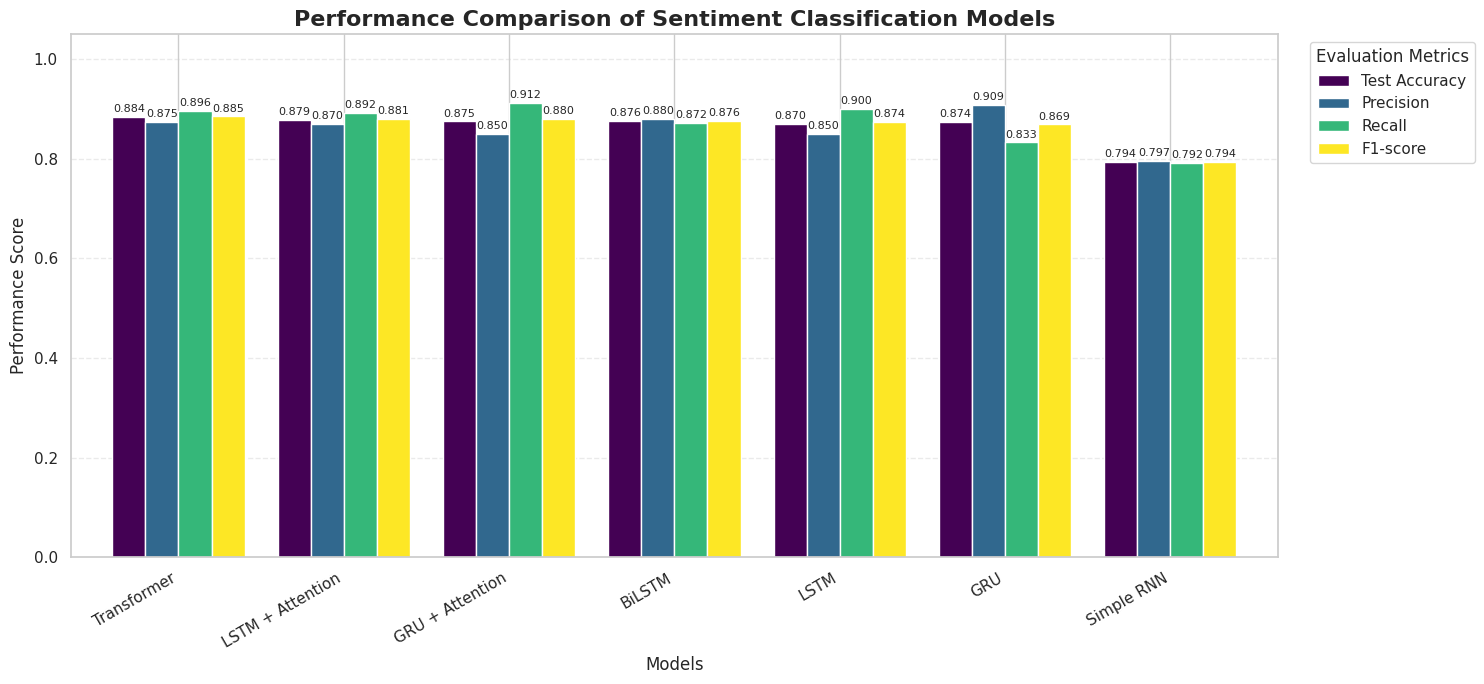

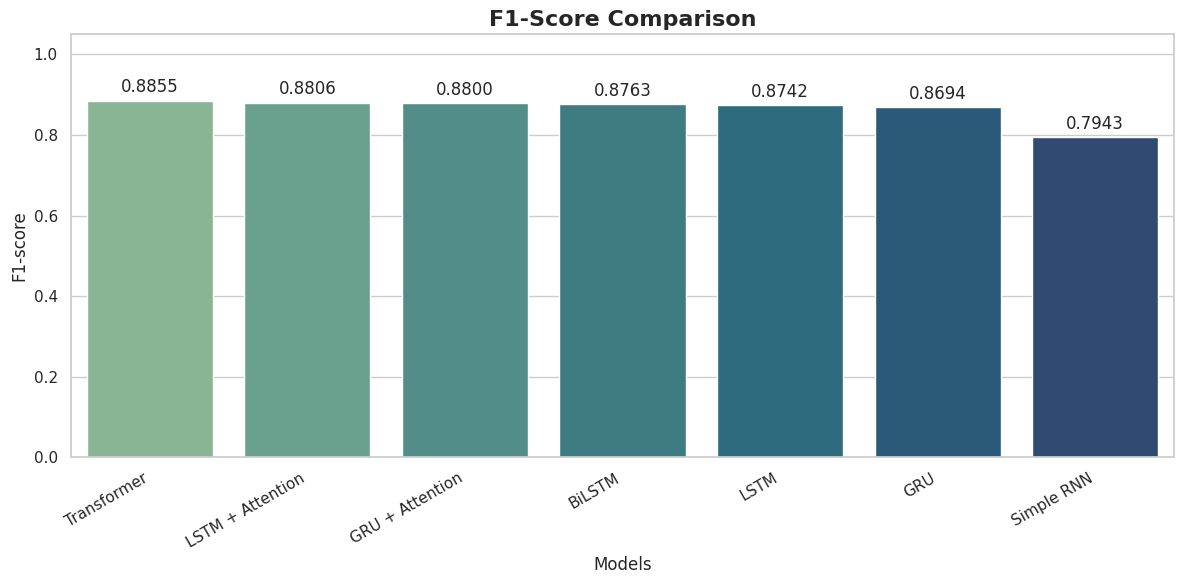

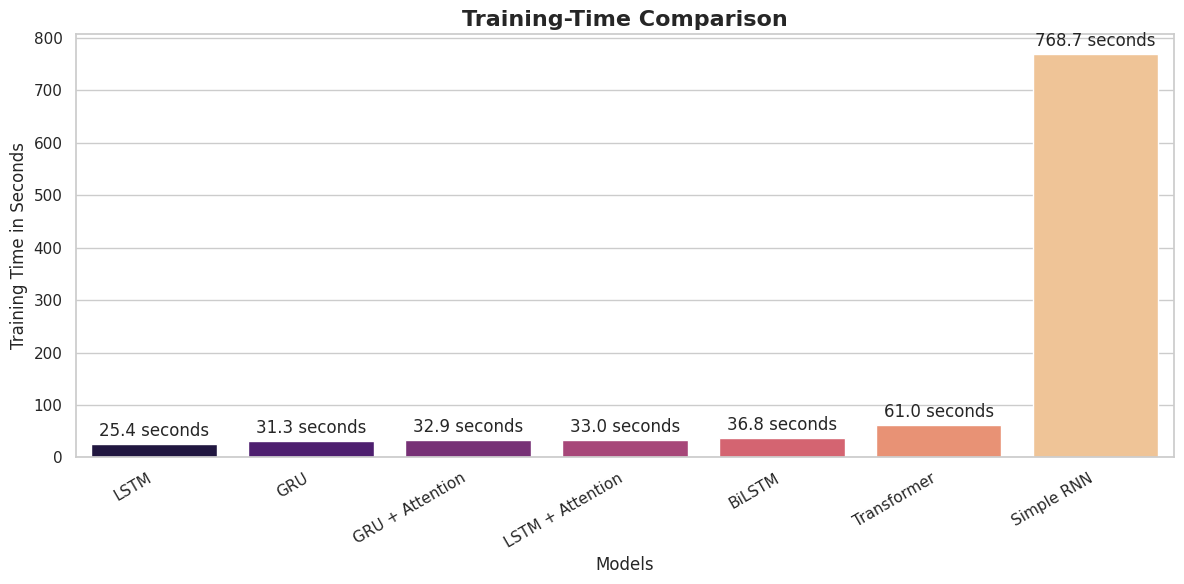

In [ ]:
#  Performance Comparison Graph for All Models
import matplotlib.pyplot as plt
import seaborn as sns

# Set the graph style
sns.set_theme(style="whitegrid")
# Graph 1: Accuracy, Precision, Recall and F1-score
# Convert the Model column into the index
performance_data = results_df.set_index("Model")

# Select only performance-metric columns
performance_metrics = performance_data[
    [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ]
]

# Create a grouped bar graph
ax = performance_metrics.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.80,
    colormap="viridis"
)

# Add graph title and labels
plt.title(
    "Performance Comparison of Sentiment Classification Models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Models",
    fontsize=12
)

plt.ylabel(
    "Performance Score",
    fontsize=12
)

# Metrics range between 0 and 1
plt.ylim(0, 1.05)

# Rotate model names
plt.xticks(
    rotation=30,
    ha="right"
)

# Add the exact value above every bar
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=8,
        padding=2
    )

# Place the legend outside the graph
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.40
)

plt.tight_layout()
plt.show()

# Graph 2: F1-score Comparison
# Arrange models from highest to lowest F1-score
f1_results = results_df.sort_values(
    by="F1-score",
    ascending=False
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=f1_results,
    x="Model",
    y="F1-score",
    palette="crest"
)

plt.title(
    "F1-Score Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Models",
    fontsize=12
)

plt.ylabel(
    "F1-score",
    fontsize=12
)

plt.ylim(0, 1.05)

plt.xticks(
    rotation=30,
    ha="right"
)

# Display value above every bar
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()
plt.show()
# Graph 3: Training-Time Comparison
# Change this to "Training Time (sec)" if that is the column
# name present in your results_df.
training_time_column = "Training Time"

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df.sort_values(
        by=training_time_column,
        ascending=True
    ),
    x="Model",
    y=training_time_column,
    palette="magma"
)

plt.title(
    "Training-Time Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Models",
    fontsize=12
)

plt.ylabel(
    "Training Time in Seconds",
    fontsize=12
)

plt.xticks(
    rotation=30,
    ha="right"
)
# Display training time above each bar
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.1f seconds",
        padding=3
    )

plt.tight_layout()
plt.show()

In [ ]:
'''
Model	Main purpose	Expected result

RNN	-------  Establish a baseline	Weak on longer dialogues

LSTM-------	Preserve longer dependencies	Better than RNN

Bidirectional LSTM  ------ 	Read context in both directions	Better input representation

Encoder–Decoder     ------  Convert dialogue into a summary	Basic sequence generation

Attention	Focus    ------   on important input words	More relevant summaries

Transformer        ------	  Use self-attention and parallel processing	Generally the best results
'''

'\nModel\tMain purpose\tExpected result\n\nRNN\tEstablish a baseline\tWeak on longer dialogues\n\nLSTM\tPreserve longer dependencies\tBetter than RNN\n\nBidirectional LSTM\tRead context in both directions\tBetter input representation\n\nEncoder–Decoder\tConvert dialogue into a summary\tBasic sequence generation\n\nAttention\tFocus on important input words\tMore relevant summaries\n\nTransformer\tUse self-attention and parallel processing\tGenerally the best results\n'